In [3]:
import os
os.chdir("/home/jovyan/work/repo_conteo_gallinas")

import pandas as pd
from siuba import *


## Grid search

In [4]:
DataGS11 = pd.read_csv("artifacts/data_comparativa_modelos_11_1.csv")
DataGS11


,numero,epocas_inicial,batch,learning_rate,optimizer,epocas_fin,total_imagenes,total_imagenes_train,total_imagenes_val,tiempo_minutos,tiempo_horas,map50,map50_95,precision,recall
0,1,50,6,0.100,SGD,50,63,50,13,1.408758,0.023479,0.38426,0.12291,0.35397,0.58957
1,2,50,6,0.100,AdamW,50,63,50,13,2.458800,0.040980,0.01589,0.00271,0.06201,0.13904
2,3,50,6,0.010,SGD,50,63,50,13,1.423165,0.023719,0.54482,0.18040,0.61843,0.58938
3,4,50,6,0.010,AdamW,50,63,50,13,1.953000,0.032550,0.30926,0.08483,0.39609,0.39840
4,5,50,6,0.001,SGD,50,63,50,13,1.435610,0.023927,0.31740,0.08761,0.38757,0.44248
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,68,150,12,0.100,AdamW,150,63,50,13,5.929683,0.098828,0.02256,0.00422,0.07179,0.18717
68,69,150,12,0.010,SGD,150,63,50,13,2.827133,0.047119,0.63468,0.22166,0.67730,0.62968
69,70,150,12,0.010,AdamW,102,63,50,13,3.966767,0.066113,0.01881,0.00440,0.07718,0.20120
70,71,150,12,0.001,SGD,150,63,50,13,2.861267,0.047688,0.58651,0.20417,0.63850,0.59225


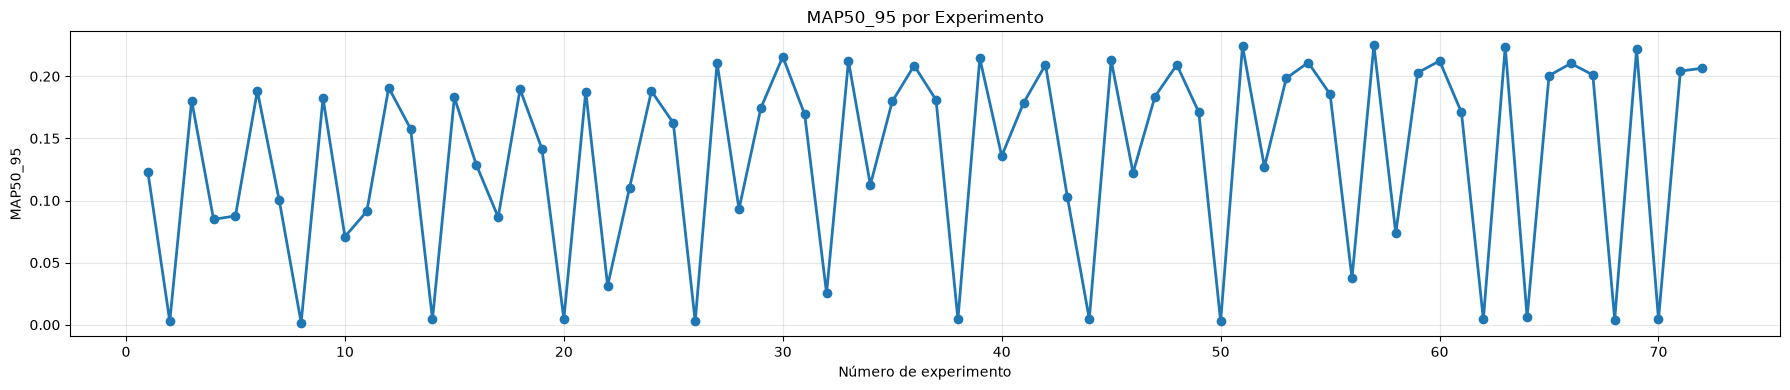

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 4))
plt.plot(
    DataGS11["numero"],
    DataGS11["map50_95"],
    marker="o",
    linewidth=2
)

plt.title("MAP50_95 por Experimento")
plt.xlabel("Número de experimento")
plt.ylabel("MAP50_95")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Optuna

In [5]:
DataOpt11 = pd.read_csv("tmp/results_opt_11.csv")
DataOpt11


,number,value,datetime_start,datetime_complete,duration,params_MODEL_BATCH,params_MODEL_EPOCHS,params_MODEL_LR,state
0,0,0.18870,2026-11-06 06:11:49.312207,2026-11-06 06:16:06.148584,0 days 00:04:16.836377,11,186,0.085329,COMPLETE
1,1,0.20200,2026-11-06 06:16:06.150086,2026-11-06 06:20:36.507803,0 days 00:04:30.357717,8,178,0.035063,COMPLETE
2,2,0.19315,2026-11-06 06:20:36.509292,2026-11-06 06:24:49.497735,0 days 00:04:12.988443,12,176,0.065615,COMPLETE
3,3,0.19125,2026-11-06 06:24:49.499180,2026-11-06 06:27:41.413230,0 days 00:02:51.914050,12,104,0.076258,COMPLETE
4,4,0.20554,2026-11-06 06:27:41.414284,2026-11-06 06:31:32.021337,0 days 00:03:50.607053,10,165,0.055331,COMPLETE
5,5,0.19036,2026-11-06 06:31:32.022889,2026-11-06 06:36:11.106652,0 days 00:04:39.083763,12,165,0.087676,COMPLETE
6,6,0.11354,2026-11-06 06:36:11.107905,2026-11-06 06:40:38.360585,0 days 00:04:27.252680,8,135,0.099090,COMPLETE
7,7,0.18028,2026-11-06 06:40:38.362142,2026-11-06 06:45:10.739913,0 days 00:04:32.377771,11,168,0.097006,COMPLETE
8,8,0.19943,2026-11-06 06:45:10.740886,2026-11-06 06:49:53.978601,0 days 00:04:43.237715,12,205,0.065218,COMPLETE
9,9,0.03615,2026-11-06 06:49:53.980255,2026-11-06 06:53:56.593678,0 days 00:04:02.613423,12,265,0.096797,COMPLETE


In [12]:
DataOpt12 = (
    DataOpt11
    >> mutate(
        numero = _.number + 1
        , map50_95 = _.value
    )
)
DataOpt12


,number,value,datetime_start,datetime_complete,duration,params_MODEL_BATCH,params_MODEL_EPOCHS,params_MODEL_LR,state,numero,map50_95
0,0,0.18870,2026-11-06 06:11:49.312207,2026-11-06 06:16:06.148584,0 days 00:04:16.836377,11,186,0.085329,COMPLETE,1,0.18870
1,1,0.20200,2026-11-06 06:16:06.150086,2026-11-06 06:20:36.507803,0 days 00:04:30.357717,8,178,0.035063,COMPLETE,2,0.20200
2,2,0.19315,2026-11-06 06:20:36.509292,2026-11-06 06:24:49.497735,0 days 00:04:12.988443,12,176,0.065615,COMPLETE,3,0.19315
3,3,0.19125,2026-11-06 06:24:49.499180,2026-11-06 06:27:41.413230,0 days 00:02:51.914050,12,104,0.076258,COMPLETE,4,0.19125
4,4,0.20554,2026-11-06 06:27:41.414284,2026-11-06 06:31:32.021337,0 days 00:03:50.607053,10,165,0.055331,COMPLETE,5,0.20554
5,5,0.19036,2026-11-06 06:31:32.022889,2026-11-06 06:36:11.106652,0 days 00:04:39.083763,12,165,0.087676,COMPLETE,6,0.19036
6,6,0.11354,2026-11-06 06:36:11.107905,2026-11-06 06:40:38.360585,0 days 00:04:27.252680,8,135,0.099090,COMPLETE,7,0.11354
7,7,0.18028,2026-11-06 06:40:38.362142,2026-11-06 06:45:10.739913,0 days 00:04:32.377771,11,168,0.097006,COMPLETE,8,0.18028
8,8,0.19943,2026-11-06 06:45:10.740886,2026-11-06 06:49:53.978601,0 days 00:04:43.237715,12,205,0.065218,COMPLETE,9,0.19943
9,9,0.03615,2026-11-06 06:49:53.980255,2026-11-06 06:53:56.593678,0 days 00:04:02.613423,12,265,0.096797,COMPLETE,10,0.03615


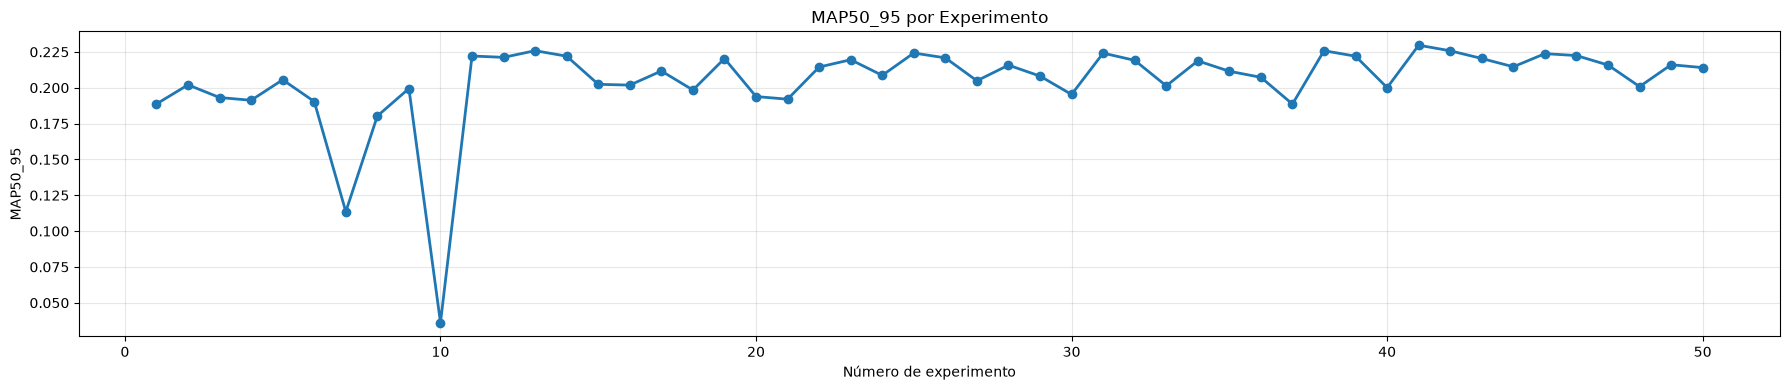

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 4))
plt.plot(
    DataOpt12["numero"],
    DataOpt12["map50_95"],
    marker="o",
    linewidth=2
)

plt.title("MAP50_95 por Experimento")
plt.xlabel("Número de experimento")
plt.ylabel("MAP50_95")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

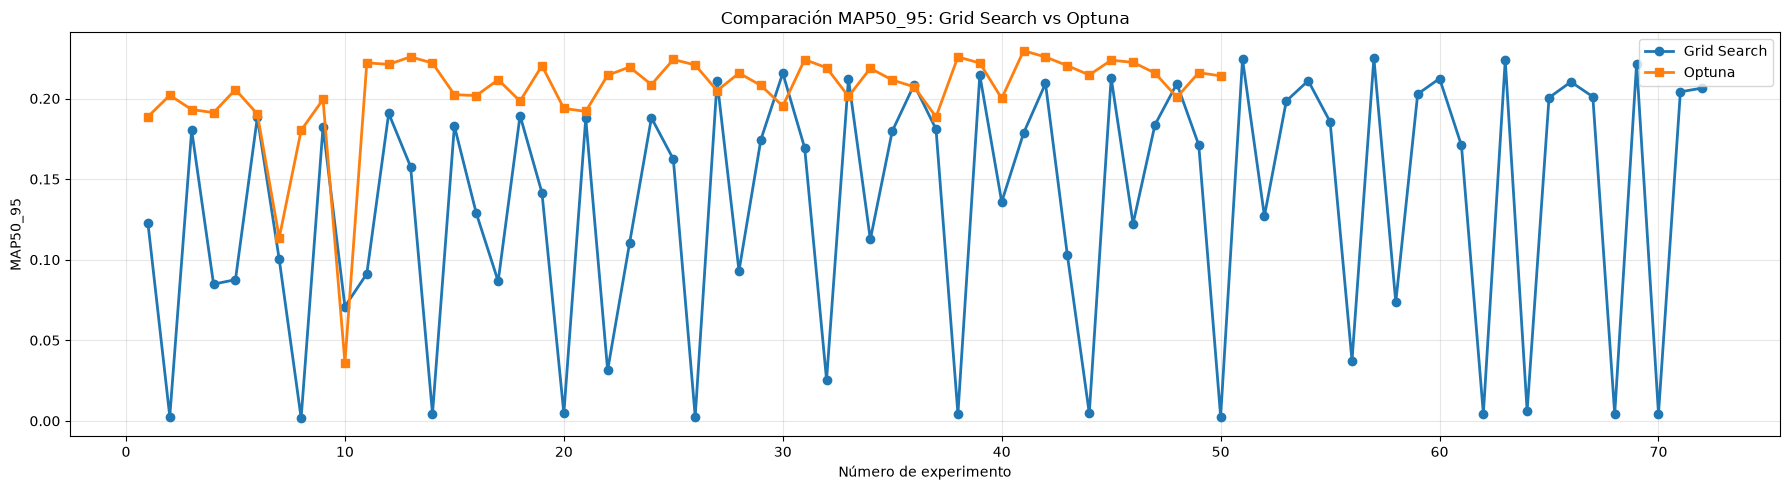

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 5))

# Grid Search
plt.plot(
    DataGS11["numero"],
    DataGS11["map50_95"],
    marker="o",
    linewidth=2,
    label="Grid Search",
    color="tab:blue"
)

# Optuna
plt.plot(
    DataOpt12["numero"],
    DataOpt12["map50_95"],
    marker="s",
    linewidth=2,
    label="Optuna",
    color="tab:orange"
)

plt.title("Comparación MAP50_95: Grid Search vs Optuna")
plt.xlabel("Número de experimento")
plt.ylabel("MAP50_95")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


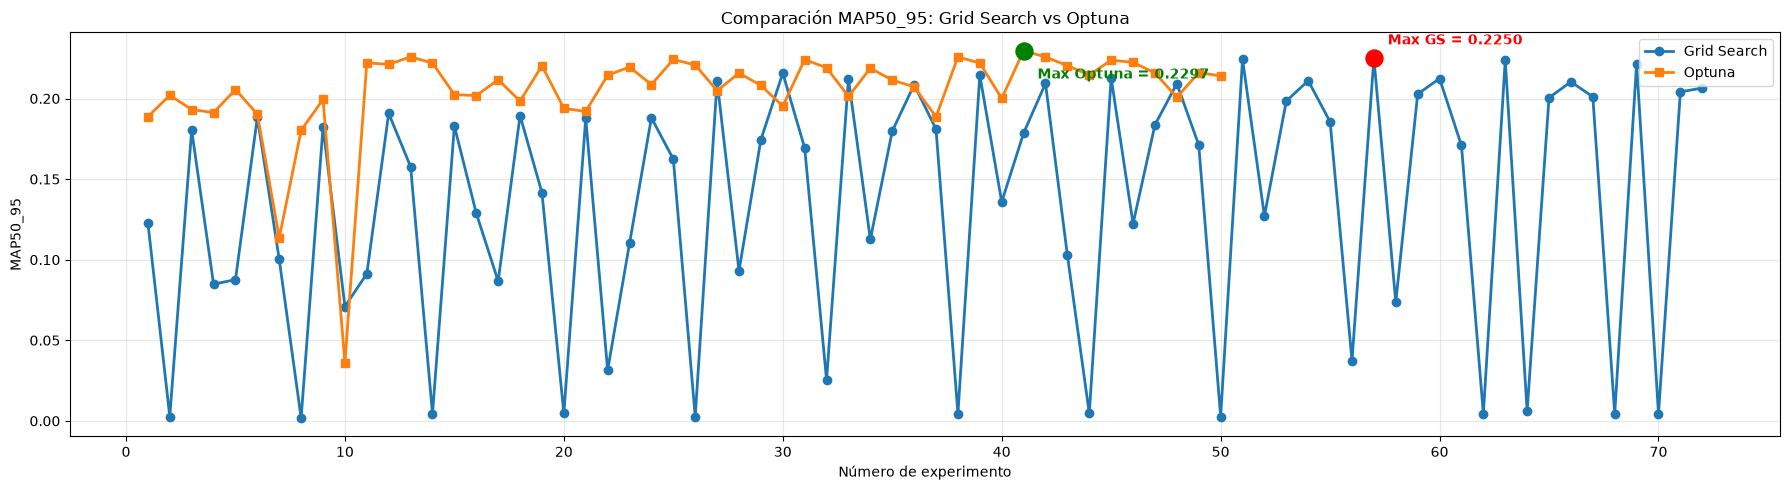

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 5))

# Gráfico de líneas
plt.plot(
    DataGS11["numero"],
    DataGS11["map50_95"],
    marker="o",
    linewidth=2,
    label="Grid Search",
    color="tab:blue"
)

plt.plot(
    DataOpt12["numero"],
    DataOpt12["map50_95"],
    marker="s",
    linewidth=2,
    label="Optuna",
    color="tab:orange"
)

# Máximo Grid Search
idx_gs = DataGS11["map50_95"].idxmax()
x_gs = DataGS11.loc[idx_gs, "numero"]
y_gs = DataGS11.loc[idx_gs, "map50_95"]

plt.scatter(x_gs, y_gs, color="red", s=150, zorder=5)
plt.annotate(
    f"Max GS = {y_gs:.4f}",
    (x_gs, y_gs),
    xytext=(10, 10),
    textcoords="offset points",
    color="red",
    fontweight="bold"
)

# Máximo Optuna
idx_opt = DataOpt12["map50_95"].idxmax()
x_opt = DataOpt12.loc[idx_opt, "numero"]
y_opt = DataOpt12.loc[idx_opt, "map50_95"]

plt.scatter(x_opt, y_opt, color="green", s=150, zorder=5)
plt.annotate(
    f"Max Optuna = {y_opt:.4f}",
    (x_opt, y_opt),
    xytext=(10, -20),
    textcoords="offset points",
    color="green",
    fontweight="bold"
)

plt.title("Comparación MAP50_95: Grid Search vs Optuna")
plt.xlabel("Número de experimento")
plt.ylabel("MAP50_95")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()